## A/B Testing, Randomized Controlled Trials

- We want to estimate the **average treatment effect**: The average difference in outcomes between the treatment and control groups
- Remember, the stakes are something like: If we implement this intervention at the scale of millions of patients, how many lives are:
    - Saved because the treatment works and our experiment showed it did (Good)
    - Not lost because the treatment doesn't work and our experiment showed it doesn't work (Good)
    - Not saved because the treatment works but our experiment failed to show it did (Bad)
    - Lost because the treatment actually harms patients, but our experiment falsely suggested it works (Very bad)

In [19]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

We generally can't compare what would have happened to observation $i$, if they had been assigned to the other treatment. This means we only observe
$$
y_{iA} = \text{Outcome for $i$ receiving treatment $A$ }
$$
or
$$
y_{iB} = \text{Outcome for $i$ receiving treatment $B$ }
$$
but not both. The **average outcome** for group $A$ is
$$
\frac{1}{\text{Size of group } A} \sum_{i \text{ receiving } A} y_{iA}
$$
and the **average outcome** for group $B$ is
$$
\frac{1}{\text{Size of group } B} \sum_{i \text{ receiving } B} y_{iB}.
$$
When we difference them, we get the **Average Treatment Effect (ATE)**:
$$
ATE = \dfrac{1}{\text{Size of group } A} \sum_{i \text{ receiving } A} y_{iA} \quad - \quad \frac{1}{\text{Size of group } B} \sum_{i \text{ receiving } B} y_{iB}
$$
As long as treatment is randomly assigned, there is no reason to think that the participants in group $A$ or $B$ are systematically different, and the **ATE** is an unbiased estimator of the true contrast in outcomes between groups $B$ and $A$. We "average away" the differences across the two groups to get an estimate of the difference in outcomes.

We then use bootstrapping to do two things:

1. Estimate the density/distribution for the averages outcomes in both groups
2. Estimate the ATE and its density/distribution

## Part 1

- First, we're going to evaluate a particular clinical trial, on chronic kidney disease:
    - ISCHEMIA-Chronic Kidney Disease Trial (ISCHEMIA-CKD)
    - ClinicalTrials.gov ID NCT01985360
    - Sponsor NYU Langone Health
    - Information provided by NYU Langone Health (Responsible Party)
- The study compared a "routine invasive therapy" (intra-aortic balloon pumps) intended to reduce death/heart attack versus more conservative medical interventions during heart surgery

<div>
<img src="./src/ischemia.png" width="700"/>
</div>

**1.** Load the `./data/iabp.csv` data. Cross tabulate `Group` and `Survived`. What is the point estimate of the ATE? Would you rather get the intra aortic balloon pump or not? Remember, A means pump and B means not.

Answer: No, according to the data below. You are slighlty less likely to survive if you get the intra aortic ballon pump. The point estimate of ATE is -.01 which favors the Conservative strategy. 

In [20]:
df = pd.read_csv('./data/iabp.csv')

## Crosstabs, average treatment effect:
print(pd.crosstab( df['Group'], df['Survived']), '\n')

ate = df.loc[ df['Group'] == 'Invasive', 'Survived'].mean() \
    - df.loc[ df['Group'] == 'Conservative', 'Survived'].mean() 
print('Estimated ATE: ', np.round(ate, 3))

Survived      0.0  1.0
Group                 
Conservative  290   99
Invasive      293   95 

Estimated ATE:  -0.01


**2.** Bootstrap the average outcome for group A, the average outcome for group B, and difference then to get the ATE, 10,000 times. Store all of these estimates. This is very important: **Bootstrap the two groups separately, since this is a clinical trial and there was random assignment (we want to maintain the balance across treatment arms).

In [21]:
## Bootstrapping:
R = 10_000

df_a = df.loc[ df['Group'] == 'Invasive',:]
df_b = df.loc[ df['Group'] == 'Conservative',:]

outcome_a = []
outcome_b = []
ate = [] # Store computed effects

for t in range(R):
    #df_t = df.sample( df.shape[0], axis=0, replace=True) # Resample

    df_at = df_a.sample(frac=1.0, replace=True)
    df_bt = df_b.sample(frac=1.0, replace=True)

    oat = df_at['Survived'].mean() # Mean outcome for A
    obt = df_bt['Survived'].mean() # Mean outcome for B    
    ate_t = oat - obt # Compute ATE for this bootstrap sample

    outcome_a.append(oat) # Save new value
    outcome_b.append(obt) # Save new value
    ate.append(ate_t) # Save new value

**3.** Make a plot of the KDEs of the outcomes for the two groups, and a plot of the ECDFs for the two groups. What relationships do you see between the two groups?

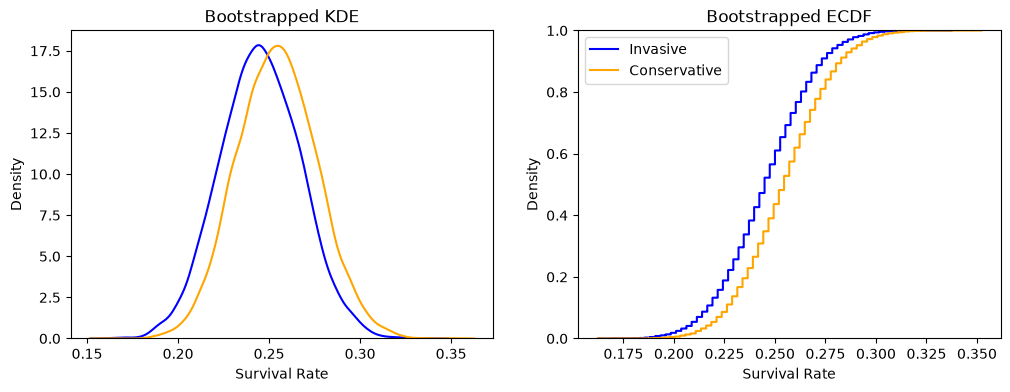

In [22]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.kdeplot(outcome_a, label='Invasive', color='blue', ax=ax[0])
sns.kdeplot(outcome_b, label='Conservative', color='orange', ax=ax[0]).set(title='Bootstrapped KDE', xlabel='Survival Rate', ylabel='Density')

sns.ecdfplot(outcome_a, label='Invasive', color='blue', ax=ax[1])
sns.ecdfplot(outcome_b, label='Conservative', color='orange', ax=ax[1]).set(title='Bootstrapped ECDF', xlabel='Survival Rate', ylabel='Density')

plt.legend()
plt.show()

**4.** Make a plot of the KDE and ECDF for the ATE. 

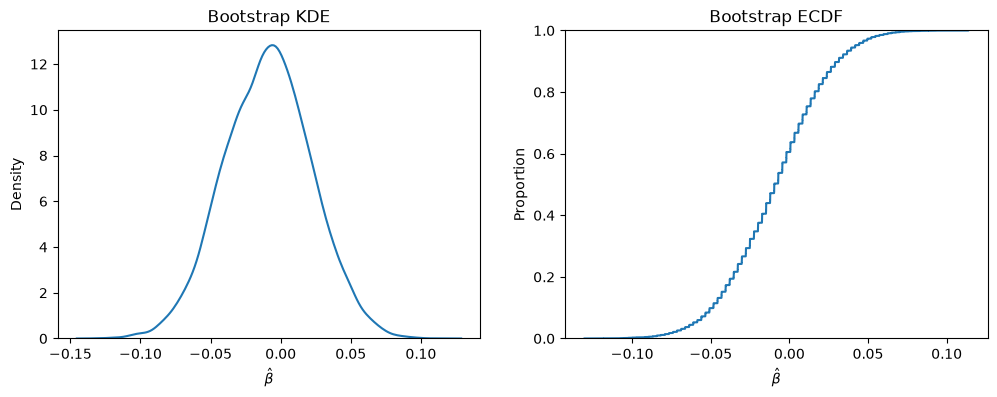

In [23]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

## KDE
sns.kdeplot(ate, ax=ax[0])
ax[0].set_xlabel(r"$\hat{\beta}$")
ax[0].set_title("Bootstrap KDE")

## ECDF
sns.ecdfplot(ate, ax=ax[1])
ax[1].set_xlabel(r"$\hat{\beta}$")
ax[1].set_title("Bootstrap ECDF")

plt.show()


**5.** Compute 90%, 95%, and 99% confidence intervals for the ATE. Is zero in those intervals? For which do we "fail to reject the null hypothesis that the effect size is zero" and for which do we "reject the null hypothesis that the effect size is zero"?

Answer: Yes, zero is in all three of these intervals. This means we "fail to reject the null hypothesis that the effect size is zero" because all three intervals have zero within their range. 

In [25]:
ci90 = np.quantile(ate, [.05, .95])
ci95 = np.quantile(ate, [.025, .975])
ci99 = np.quantile(ate, [.005, .995])

print(f"90% CI: {ci90}")
print(f"95% CI: {ci95}")
print(f"99% CI: {ci99}")

90% CI: [-0.06112024  0.04184003]
95% CI: [-0.07139656  0.05209647]
99% CI: [-0.08945091  0.07013768]


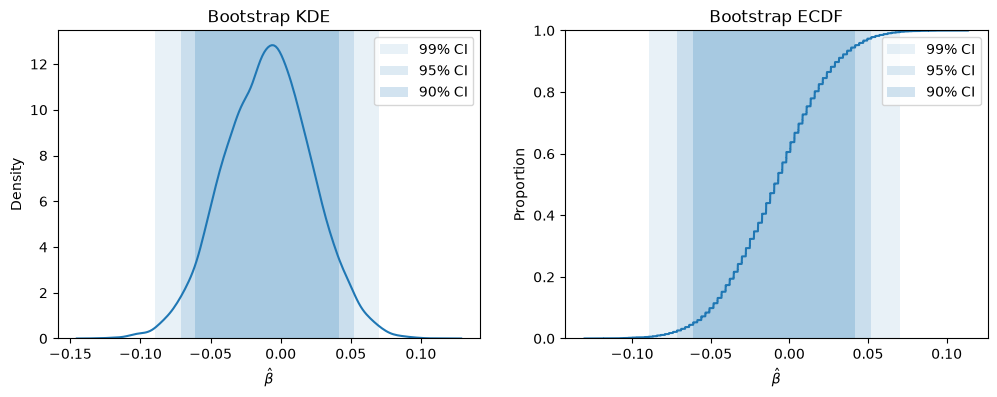

In [26]:
# Percentile bootstrap confidence intervals
ci90 = np.quantile(ate, [.05, .95])
ci95 = np.quantile(ate, [.025, .975])
ci99 = np.quantile(ate, [.005, .995])

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

## KDE
sns.kdeplot(ate, ax=ax[0])

ax[0].axvspan(ci99[0], ci99[1], alpha=0.10, label="99% CI")
ax[0].axvspan(ci95[0], ci95[1], alpha=0.15, label="95% CI")
ax[0].axvspan(ci90[0], ci90[1], alpha=0.20, label="90% CI")

ax[0].set_xlabel(r"$\hat{\beta}$")
ax[0].set_title("Bootstrap KDE")
ax[0].legend()

## ECDF
sns.ecdfplot(ate, ax=ax[1])

ax[1].axvspan(ci99[0], ci99[1], alpha=0.10, label="99% CI")
ax[1].axvspan(ci95[0], ci95[1], alpha=0.15, label="95% CI")
ax[1].axvspan(ci90[0], ci90[1], alpha=0.20, label="90% CI")

ax[1].set_xlabel(r"$\hat{\beta}$")
ax[1].set_title("Bootstrap ECDF")
ax[1].legend()

**6.** What have we learned about inserting balloons into hearts?

Answer: There is no significant evidence that sugests inserting ballons into hearts reduces death/heart attacks versus more conservative medical interventions during heart surgery. 

# Part 2

In `./data/diabetes.csv`, there is data from a clinical trial considering three treatments for pre-diabetics to reduce the progression to full diabetes: metformin, rosiglitazone, and lifestyle adjustments (diet, exercise). Unlike Part 1, there aren't two treatment arms (i.e. A = aortic balloon, B = no aortic balloon), but three (met, rosi, lifestyle).

You are a data analyst working for `clinicaltrials.gov` and the FDA to provide an unbiased review of the trial's results. The researchers have provided you with `./data/diabests.csv`.

In an ipynb or py file:

1. Load the `./data/diabetes.csv` data. Cross tabulate the outcomes for the three groups. What are the average outcomes for the three groups? 
2. Bootstrap the outcomes for the three groups 10,000 times. Store all of these estimates. As this is another randomized controlled trial, do the resampling within the arms. 
3. Plot the three densities on one plot and three distributions on another. Describe any patterns you see.
4. There are three treatment effects: met versus rosi, met versus lifestyle, rosi versus lifestyle. Make KDE and ECDF plots of all these comparisons.
5. Compute confidence intervals for each pairwise ATE based on its ECDF (percentile bootstrap). Do you find any statistically significant differences between the interventions? Which seems the most effective?

Then:

6. Write a short report (3-5 paragraphs) that summarizes the evidence from the trial for adopting each of the interventions or not. Use tables and visualizations. Write in a professional tone for a technical audience, and focus on evidence (or the lack thereof). Do not assume anyone has read your work in your notebooks.

1. Load the `./data/diabetes.csv` data. Cross tabulate the outcomes for the three groups. What are the average outcomes for the three groups? 

In [27]:
df = pd.read_csv('./data/diabetes.csv')

df['success'] = df['outcome'].map({'success': 1, 'failure': 0})


## Crosstabs, average treatment effect:
print(pd.crosstab( df['treatment'], df['success']), '\n')

ate_met_rosi = df.loc[ df['treatment'] == 'met', 'success'].mean() \
    - df.loc[ df['treatment'] == 'rosi', 'success'].mean() 
print('Estimated ATE Met and Rosi: ', np.round(ate_met_rosi, 3))

ate_met_lifestyle = df.loc[ df['treatment'] == 'met', 'success'].mean() \
    - df.loc[ df['treatment'] == 'lifestyle', 'success'].mean() 
print('Estimated ATE Met and Lifestyle: ', np.round(ate_met_lifestyle, 3))

ate_rosi_lifestyle = df.loc[ df['treatment'] == 'rosi', 'success'].mean() \
    - df.loc[ df['treatment'] == 'lifestyle', 'success'].mean() 
print('Estimated ATE Rosi and Lifestyle: ', np.round(ate_rosi_lifestyle, 3))

success      0    1
treatment          
lifestyle  109  125
met        120  112
rosi        90  143 

Estimated ATE Met and Rosi:  -0.131
Estimated ATE Met and Lifestyle:  -0.051
Estimated ATE Rosi and Lifestyle:  0.08


2. Bootstrap the outcomes for the three groups 10,000 times. Store all of these estimates. As this is another randomized controlled trial, do the resampling within the arms. 

In [28]:

## Bootstrapping:
R = 10_000

df_lifestyle = df.loc[ df['treatment'] == 'lifestyle',:]
df_met = df.loc[ df['treatment'] == 'met',:]
df_rosi = df.loc[ df['treatment'] == 'rosi',:]

outcome_lifestyle = []
outcome_met = []
outcome_rosi = []
ate_lifestyle_met = [] # Store computed effects
ate_lifestyle_rosi = [] 
ate_met_rosi = [] 

for t in range(R):
    #df_t = df.sample( df.shape[0], axis=0, replace=True) # Resample

    df_at = df_lifestyle.sample(frac=1.0, replace=True)
    df_bt = df_met.sample(frac=1.0, replace=True)
    df_ct = df_rosi.sample(frac=1.0, replace=True)

    oat = df_at['success'].mean() # Mean outcome for A
    obt = df_bt['success'].mean() # Mean outcome for B
    oct = df_ct['success'].mean() # Mean outcome for C
    ate_lifestyle_met_t = oat - obt # Compute ATE for this bootstrap sample
    ate_lifestyle_rosi_t = oat - oct 
    ate_met_rosi_t = obt - oct 



    outcome_lifestyle.append(oat) # Save new value
    outcome_met.append(obt) 
    outcome_rosi.append(oct) 
    ate_lifestyle_met.append(ate_lifestyle_met_t) # Save new value
    ate_lifestyle_rosi.append(ate_lifestyle_rosi_t) 
    ate_met_rosi.append(ate_met_rosi_t) 

3. Plot the three densities on one plot and three distributions on another. Describe any patterns you see.

The plots seen to show 3 normal distributions with different means. Metformin treatment on the left has the lowest average survival rate while the rosiglitazone treatment on the right side of the plot has the highest average survival rate. 

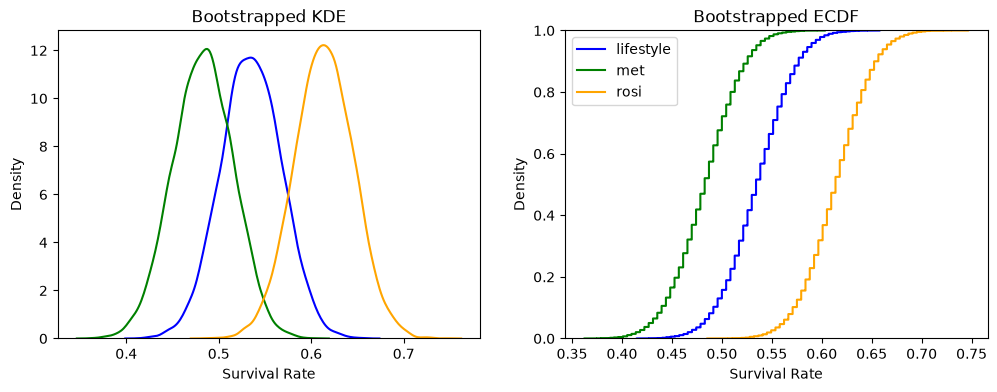

In [29]:

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.kdeplot(outcome_lifestyle, label='lifestyle', color='blue', ax=ax[0])
sns.kdeplot(outcome_met, label='met', color='green', ax=ax[0])
sns.kdeplot(outcome_rosi, label='rosi', color='orange', ax=ax[0]).set(title='Bootstrapped KDE', xlabel='Survival Rate', ylabel='Density')

sns.ecdfplot(outcome_lifestyle, label='lifestyle', color='blue', ax=ax[1])
sns.ecdfplot(outcome_met, label='met', color='green', ax=ax[1])
sns.ecdfplot(outcome_rosi, label='rosi', color='orange', ax=ax[1]).set(title='Bootstrapped ECDF', xlabel='Survival Rate', ylabel='Density')

plt.legend()
plt.show()

4. There are three treatment effects: met versus rosi, met versus lifestyle, rosi versus lifestyle. Make KDE and ECDF plots of all these comparisons.

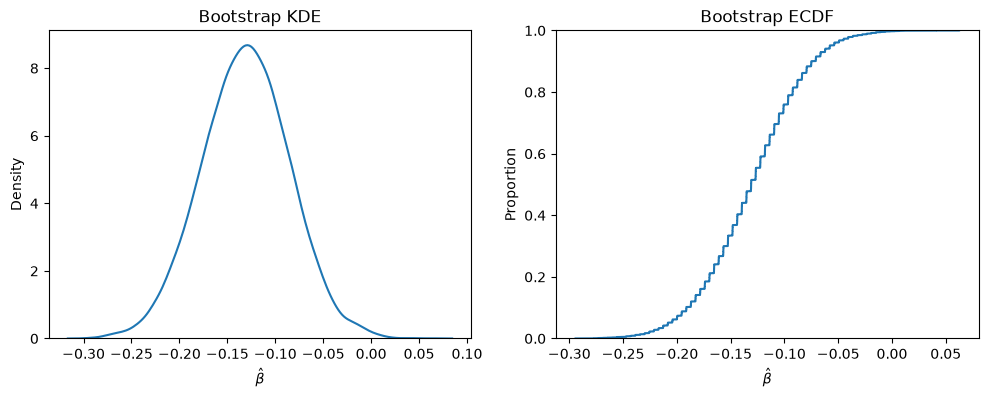

In [30]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

## KDE met and rosi
sns.kdeplot(ate_met_rosi, ax=ax[0])
ax[0].set_xlabel(r"$\hat{\beta}$")
ax[0].set_title("Bootstrap KDE")

## ECDF met and rosi
sns.ecdfplot(ate_met_rosi, ax=ax[1])
ax[1].set_xlabel(r"$\hat{\beta}$")
ax[1].set_title("Bootstrap ECDF")
plt.show()


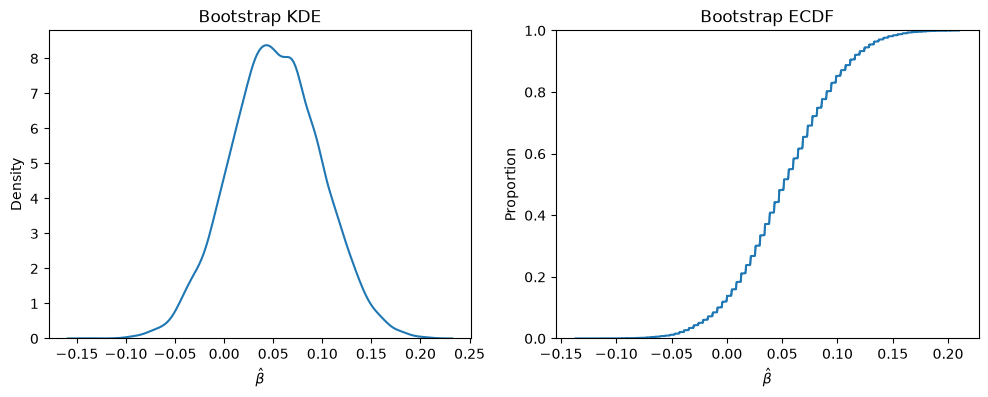

In [31]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
## KDE liferstyle and met
sns.kdeplot(ate_lifestyle_met, ax=ax[0])
ax[0].set_xlabel(r"$\hat{\beta}$")
ax[0].set_title("Bootstrap KDE")

## ECDF lifestyle and met
sns.ecdfplot(ate_lifestyle_met, ax=ax[1])
ax[1].set_xlabel(r"$\hat{\beta}$")
ax[1].set_title("Bootstrap ECDF")
plt.show()

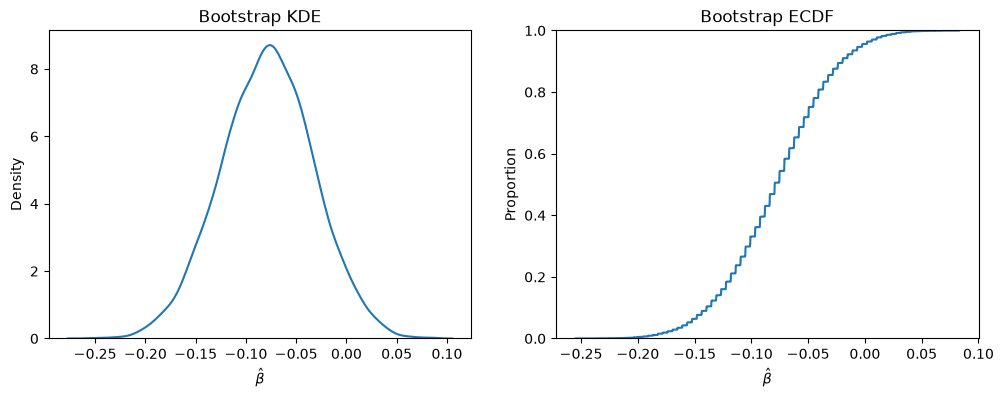

In [32]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
## KDE rosi and lifestyle
sns.kdeplot(ate_lifestyle_rosi, ax=ax[0])
ax[0].set_xlabel(r"$\hat{\beta}$")
ax[0].set_title("Bootstrap KDE")

## ECDF rosi and lifestyle
sns.ecdfplot(ate_lifestyle_rosi, ax=ax[1])
ax[1].set_xlabel(r"$\hat{\beta}$")
ax[1].set_title("Bootstrap ECDF")
plt.show()

5. Compute confidence intervals for each pairwise ATE based on its ECDF (percentile bootstrap). Do you find any statistically significant differences between the interventions? Which seems the most effective?

Answer: The confidence intervals for the three treatments for pre-diabetics to reduce the progression to full diabetes. It seems there is a signifiant differnet between metformin, and rosiglitazone on all the 90th, 95th, and 99th percentile. The rosiglitazone has signifiantly more "success" than metformin. In all other comparisons, with the exception of lifestyle vs rosiglitazone at the 90th percentile, there is no significant differences between any of the treatments because 0 is in the confidence intervals. Overall, rosiglitazone seems to be the most affective treatment. Rosiglitazone is signifiantly more successful than metformin and also signifiantly more successful than lifestyle at the 90 percentile. 

In [38]:
# Percentile bootstrap confidence intervals for met and rosi
ci90 = np.quantile(ate_met_rosi, [.05, .95])
ci95 = np.quantile(ate_met_rosi, [.025, .975])
ci99 = np.quantile(ate_met_rosi, [.005, .995])
print(f"90% CI: {ci90}")
print(f"95% CI: {ci95}")
print(f"99% CI: {ci99}")


90% CI: [-0.208321   -0.05777342]
95% CI: [-0.22128903 -0.04069853]
99% CI: [-0.25149854 -0.01058162]


In [39]:
# Percentile bootstrap confidence intervals lifestyle and met
ci90 = np.quantile(ate_lifestyle_met, [.05, .95])
ci95 = np.quantile(ate_lifestyle_met, [.025, .975])
ci99 = np.quantile(ate_lifestyle_met, [.005, .995])
print(f"90% CI: {ci90}")
print(f"95% CI: {ci95}")
print(f"99% CI: {ci99}")


90% CI: [-0.02556734  0.12868406]
95% CI: [-0.03853522  0.14165193]
99% CI: [-0.06472904  0.16786214]


In [40]:
# Percentile bootstrap confidence intervals lifestyle and rosi
ci90 = np.quantile(ate_lifestyle_rosi, [.05, .95])
ci95 = np.quantile(ate_lifestyle_rosi, [.025, .975])
ci99 = np.quantile(ate_lifestyle_rosi, [.005, .995])
print(f"90% CI: {ci90}")
print(f"95% CI: {ci95}")
print(f"99% CI: {ci99}")

90% CI: [-0.15656065 -0.00249441]
95% CI: [-0.1695279  0.0104545]
99% CI: [-0.19924113  0.0361323 ]
